# Practical 2: Implement a Feedforward Neural Network using TensorFlow and Keras

## Aim
To implement a feedforward neural network using TensorFlow/Keras, train it on the MNIST handwritten-digit dataset using Stochastic Gradient Descent (SGD), evaluate its performance, and plot training/validation loss and accuracy.

## Software and libraries
- Python 3.11
- TensorFlow (includes Keras)
- NumPy
- Matplotlib
- Jupyter Notebook

**Dataset:** MNIST contains 28 × 28 grayscale images of handwritten digits (0–9). Keras downloads the dataset automatically the first time this notebook is run, so an internet connection is required.

**Environment:** Select the `Python 3.11 (DL Practicals)` kernel created for Practical 1. This notebook runs on CPU; a GPU is not required.

In [2]:
%pip install matplotlib

  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -------- ------------------------------- 2.1/9.3 MB 11.8 MB/s eta 0:00:01
   ----------------- ---------------------- 4.2/9.3 MB 10.1 MB/s eta 0:00:01
   ---------------------------- ----------- 6.6/9.3 MB 10.6 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 11.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 10.6 MB/s  0:00:00
Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 9.1 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## 1. Import required libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

Matplotlib is building the font cache; this may take a moment.


TensorFlow version: 2.21.0
NumPy version: 2.4.6


## 2. Load the MNIST dataset
The dataset is divided into training data and test data. The training set is used to learn model parameters; the test set is held back for final evaluation.

In [4]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 3. Explore sample images

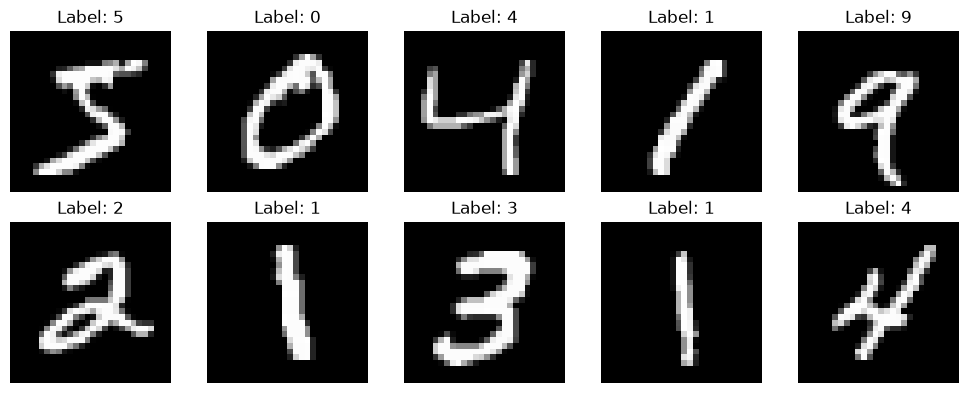

In [5]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Preprocess the data

- Convert pixel values from the range 0–255 to 0–1 by dividing by 255.
- Keep labels as integers from 0 to 9. Therefore, `sparse_categorical_crossentropy` is suitable as the loss function.

In [6]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Normalized training pixel range:", x_train.min(), "to", x_train.max())
print("Normalized test pixel range:", x_test.min(), "to", x_test.max())

Normalized training pixel range: 0.0 to 1.0
Normalized test pixel range: 0.0 to 1.0


## 5. Define the feedforward neural network
The network flattens each 28 × 28 image into 784 features, passes them through a hidden dense layer with 128 ReLU neurons, and produces probabilities for the 10 digit classes using softmax.

In [7]:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the model using SGD
SGD (Stochastic Gradient Descent) is used as the optimizer. Sparse categorical cross-entropy is used because the target labels are integer class IDs.

In [8]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


## 7. Train the model
The model is trained for five epochs. Validation data is taken from the test set here to display learning progress; the test metrics will also be reported after training.

In [9]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test),
    verbose=1
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8377 - loss: 0.6530 - val_accuracy: 0.9017 - val_loss: 0.3582
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9056 - loss: 0.3380 - val_accuracy: 0.9200 - val_loss: 0.2926
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9190 - loss: 0.2892 - val_accuracy: 0.9286 - val_loss: 0.2627
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9281 - loss: 0.2585 - val_accuracy: 0.9331 - val_loss: 0.2385
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9345 - loss: 0.2354 - val_accuracy: 0.9391 - val_loss: 0.2191


## 8. Evaluate the trained model on the test set

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

Test loss: 0.2191
Test accuracy: 0.9391 (93.91%)


## 9. Plot training and validation loss

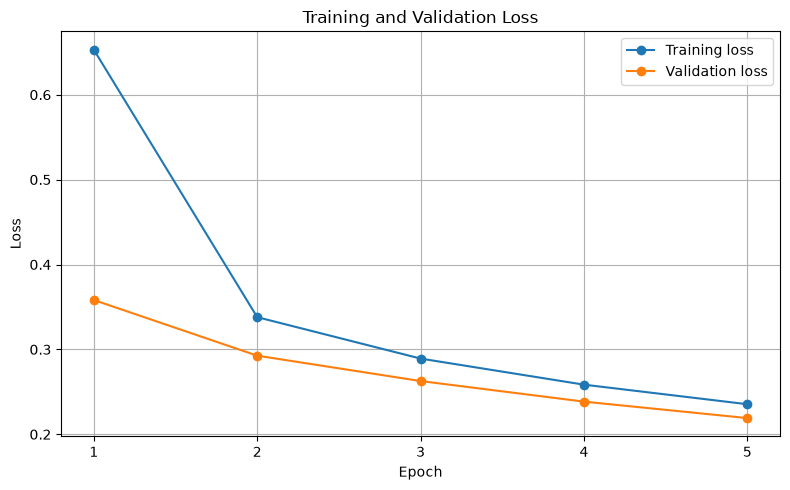

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(len(history.history["loss"])), range(1, len(history.history["loss"]) + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. Plot training and validation accuracy

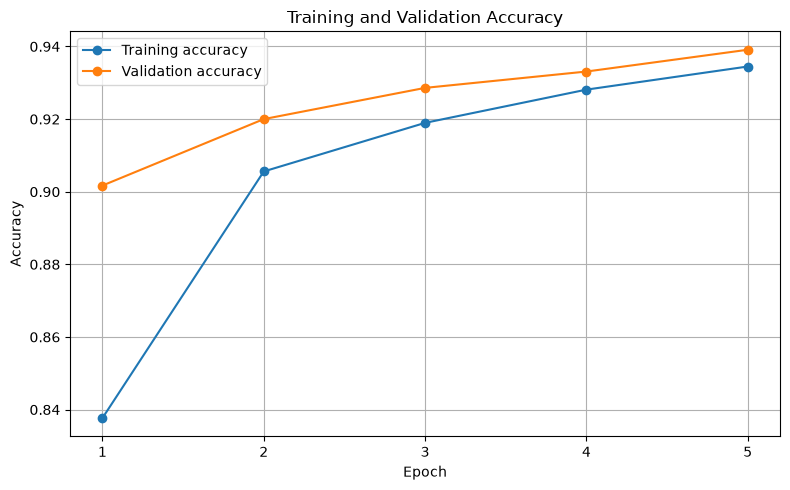

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(range(len(history.history["accuracy"])), range(1, len(history.history["accuracy"]) + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 11. Display a few predictions
This cell displays the model's predicted digit and the actual label for a few test images.

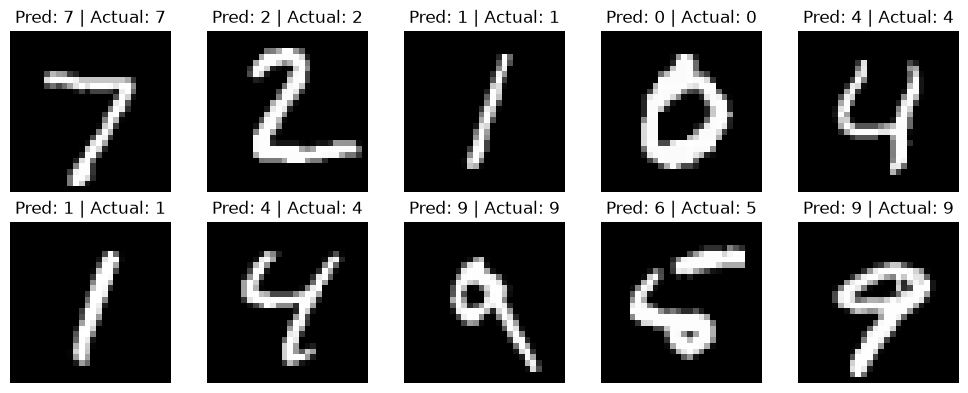

In [13]:
predicted_probabilities = model.predict(x_test[:10], verbose=0)
predicted_labels = np.argmax(predicted_probabilities, axis=1)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Pred: {predicted_labels[i]} | Actual: {y_test[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Result and conclusion

A feedforward neural network was implemented using TensorFlow/Keras and trained on the MNIST handwritten-digit dataset using the SGD optimizer. The model was evaluated on the test dataset, and training/validation loss and accuracy were plotted to observe its learning performance.

**Record the test loss and test accuracy printed in Section 8 after running the notebook.** Exact values may vary slightly depending on the environment and training run.